# 02 — Pré-processamento

**Objetivo.** Transformar as duas bases brutas em uma tabela pronta para modelar, com uma
linha por conta. Cada decisão está justificada no texto e implementada em
`src/preprocessing.py`, para que os notebooks seguintes e o `run_pipeline.py` usem exatamente
o mesmo código.

Uma regra vale para o notebook inteiro: aqui só entram transformações **fixas**, que não
aprendem nada com os dados (converter dias em anos, truncar em um valor definido, criar uma
razão). Tudo que depende de estatísticas da base (escala, agrupamento de categorias raras,
one-hot) fica dentro do `Pipeline` do notebook 03, ajustado apenas nos folds de treino. É o
que impede informação do teste de vazar para o treino.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))   # permite `from src... import ...`

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import (COR_APOIO, COR_BOM, COR_MAU, COR_NEUTRA, FEATURE_SETS, GROUP,
                        JANELA_MESES, STATUS_MAU)
from src.data import load_raw, save_processed
from src.plots import save, set_style
from src.preprocessing import (add_client_id, build_dataset, build_features,
                               build_history_features, build_target, check_missing,
                               clean_application, prepare_credit)

# Semente fixa: usada em TODO ponto com aleatoriedade (split, modelos, CV).
RANDOM_STATE = 42

RAW = Path("..") / "data" / "raw"
PROCESSED = Path("..") / "data" / "processed"
TARGET = "MAU_PAGADOR"

pd.set_option("display.max_columns", None)
set_style()

In [2]:
app, credit = load_raw()
app.shape, credit.shape

((438557, 18), (1048575, 3))

## 1. Dados faltantes

In [3]:
display(check_missing(app))
display(check_missing(credit))
sem_ocup = app[app["OCCUPATION_TYPE"].isna()]
pd.crosstab(sem_ocup["NAME_INCOME_TYPE"], sem_ocup["DAYS_EMPLOYED"] == 365243,
            margins=True).rename(columns={False: "com vínculo", True: "sem vínculo (365243)"})

,nulos,pct
OCCUPATION_TYPE,134203,30.6


,nulos,pct


DAYS_EMPLOYED,com vínculo,sem vínculo (365243),All
NAME_INCOME_TYPE,,,
Commercial associate,16745,0,16745
Pensioner,28,75329,75357
State servant,6210,0,6210
Student,5,0,5
Working,35886,0,35886
All,58874,75329,134203


**Leitura.** Só `OCCUPATION_TYPE` tem nulos: 134.203 fichas (30,6%). O histórico de crédito
não tem nenhum. A tabela mostra que o nulo tem duas origens bem distintas:

- **75.329 são aposentados sem vínculo** (`DAYS_EMPLOYED = 365243`). Para eles a ocupação não
  está faltando: ela não existe.
- **58.874 têm vínculo de emprego** e simplesmente não informaram a ocupação.

**Decisão.** Nenhuma linha é descartada e nenhum valor é inventado. Os nulos viram duas
categorias explícitas: `Pensioner (no job)` e `Not informed`. Imputar a moda ("Laborers")
atribuiria uma profissão a 31% da base, e descartar as linhas jogaria fora quase um terço dos
clientes. Tratar o nulo como categoria ainda deixa o modelo verificar se "não informar" diz
algo sobre o risco (a EDA mostrou que não: 1,3% de maus, abaixo da média).

## 2. Duplicatas e identidade do cliente

In [4]:
dup = app[app["ID"].duplicated(keep=False)].sort_values("ID")
print(f"IDs repetidos: {dup['ID'].nunique()} ({len(dup)} linhas) | "
      f"algum deles tem histórico de crédito? {dup['ID'].isin(credit['ID']).any()}")
display(dup.head(4))

app_id = add_client_id(app)
com_hist = app_id[app_id["ID"].isin(credit["ID"]) & ~app_id["ID"].duplicated(keep=False)]
contas_por_cliente = com_hist.groupby(GROUP).size()
print(f"Contas com histórico: {len(com_hist):,} | clientes distintos: {len(contas_por_cliente):,} | "
      f"média de {contas_por_cliente.mean():.1f} contas por cliente | "
      f"{(contas_por_cliente > 1).mean():.0%} dos clientes têm mais de uma")
contas_por_cliente.describe().to_frame("contas por cliente").T

IDs repetidos: 47 (94 linhas) | algum deles tem histórico de crédito? False


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
425023,7022197,F,N,Y,0,450000.0,Commercial associate,Higher education,Separated,House / apartment,-19813,-1799,1,0,0,1,NaN,1.0
426818,7022197,M,Y,Y,3,135000.0,Working,Secondary / secondary special,Married,House / apartment,-11945,-735,1,0,0,1,Laborers,5.0
431911,7022327,M,Y,Y,0,256500.0,Commercial associate,Higher education,Married,House / apartment,-21503,-1674,1,0,0,1,Core staff,2.0
431545,7022327,F,N,Y,0,135000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-14771,-5298,1,0,0,0,High skill tech staff,1.0


Contas com histórico: 36,457 | clientes distintos: 9,728 | média de 3.7 contas por cliente | 68% dos clientes têm mais de uma


,count,mean,std,min,25%,50%,75%,max
contas por cliente,9728.0,3.747636,3.372819,1.0,1.0,3.0,5.0,51.0


**Leitura e decisões.**

- **IDs duplicados.** 47 IDs aparecem duas vezes com fichas totalmente diferentes (gênero,
  renda e idade distintos). Não há critério para escolher a ficha certa e nenhum deles tem
  histórico de crédito. **Decisão: remover as 94 linhas.**
- **Identidade do cliente.** A base não traz identificador de pessoa, só de conta. Fichas
  idênticas em todos os 17 atributos são tratadas como o mesmo cliente e recebem o mesmo
  `ID_CLIENTE`. O resultado: 36.457 contas pertencem a 9.728 clientes, e 68% deles têm mais
  de uma conta.

`ID_CLIENTE` não entra como atributo do modelo. Ele serve a dois propósitos: (1) manter
todas as contas de um cliente do mesmo lado no split e na validação cruzada e (2) permitir
calcular o comportamento do cliente em contas anteriores (seção 6).

*Hipótese assumida:* duas pessoas diferentes dificilmente coincidem em 17 atributos,
incluindo a data de nascimento e a de admissão medidas em dias. Se isso acontecer, o efeito
é conservador para a validação (contas a mais no mesmo grupo), mas contaminaria o histórico
de um cliente com o de outro. É uma limitação registrada no notebook 04.

## 3. Definição da variável alvo

A base não traz o rótulo pronto: "bom" e "mau" pagador precisam ser definidos a partir do
`STATUS` mensal. Duas perguntas precisam de resposta, e as duas são respondidas com os dados
e não por convenção:

- **(a) A partir de quantos dias de atraso a conta é "má"?**
- **(b) Em que período o atraso é observado?**

In [5]:
cr = prepare_credit(credit[credit["ID"].isin(com_hist["ID"])])
por_conta = cr.groupby("ID").agg(meses=("MOB", "count"), pior=("SEV", "max"))

# (a) Taxa de rolagem: de quem chegou a um nível de atraso, quantos pioraram depois?
niveis = {0: "1–29 dias", 1: "30–59 dias", 2: "60–89 dias", 3: "90–119 dias", 4: "120–149 dias"}
rolagem = pd.DataFrame([
    {"chegou a": niveis[k], "contas": int((por_conta["pior"] >= k).sum()),
     "pioraram (%)": 100 * (por_conta.loc[por_conta["pior"] >= k, "pior"] >= k + 1).mean()}
    for k in niveis])
rolagem

,chegou a,contas,pioraram (%)
0,1–29 dias,32002,13.408537
1,30–59 dias,4291,14.355628
2,60–89 dias,616,49.025974
3,90–119 dias,302,74.834437
4,120–149 dias,226,79.646018


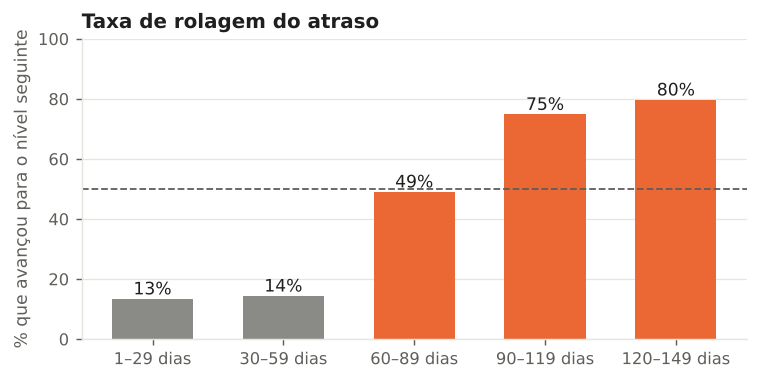

In [6]:
fig, ax = plt.subplots(figsize=(6.6, 3.0))
cores = [COR_NEUTRA, COR_NEUTRA, COR_MAU, COR_MAU, COR_MAU]
ax.bar(rolagem["chegou a"], rolagem["pioraram (%)"], color=cores, width=0.62)
for i, v in enumerate(rolagem["pioraram (%)"]):
    ax.text(i, v + 1.5, f"{v:.0f}%", ha="center")
ax.axhline(50, color="#5f5e5a", lw=1, ls="--")
ax.set_ylim(0, 100)
ax.set_ylabel("% que avançou para o nível seguinte")
ax.set_title("Taxa de rolagem do atraso")
ax.grid(axis="x", visible=False)
save(fig, "02_taxa_rolagem")
plt.show()

**Leitura — (a) por que 60 dias.** A taxa de rolagem mostra, de quem chegou a um nível de
atraso, quantos pioraram depois. Entre as contas que chegaram a 30–59 dias, só **14%**
avançaram: 86% regularizaram. É atraso que se resolve, e chamá-lo de "mau pagador"
classificaria como ruim um cliente que o banco quer manter. A partir de 60–89 dias o quadro
muda: **49%** seguem piorando, e depois de 90 dias são 75% ou mais. Os 60 dias são o ponto em
que o atraso deixa de ser um esquecimento e passa a ser um problema com chance real de virar
perda. **Limiar adotado: `STATUS >= 2` (60 dias ou mais).**

,contas,pct_60_mais
tempo observado,,
1–6,5944,0.29
7–12,7094,0.89
13–18,5856,1.02
19–24,4410,1.50
25–36,6502,1.78
37–48,4212,3.80
49–61,2439,5.49


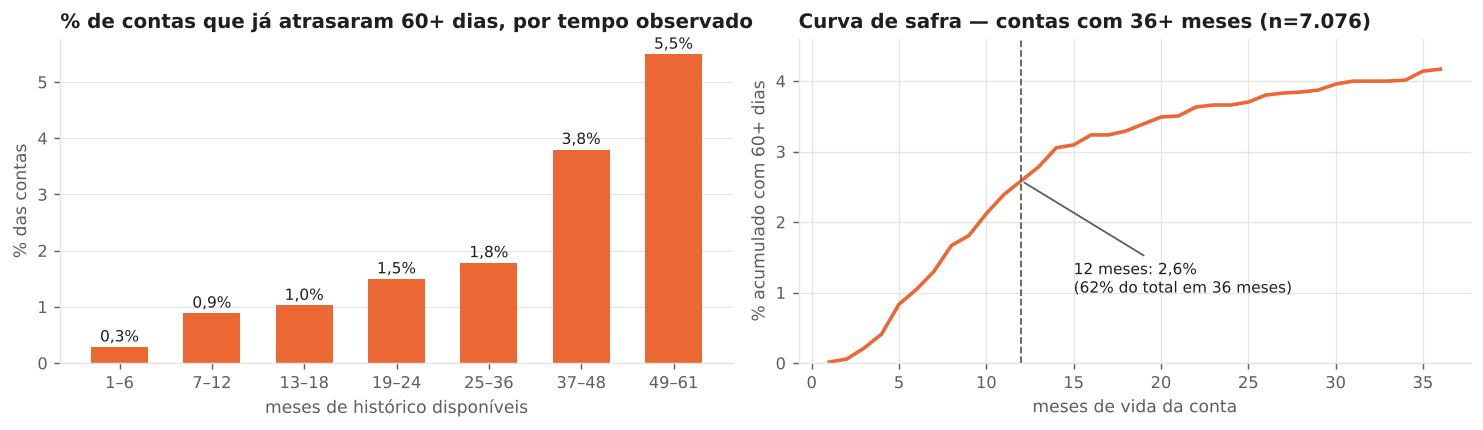

Mês de vida do primeiro atraso 60+: mediana 10, 75% até o mês 15


In [7]:
# (b) Efeito do tempo de observação: quanto mais tempo a conta é observada,
#     mais chance ela tem de aparecer com atraso.
por_conta["tempo observado"] = pd.cut(por_conta["meses"], [0, 6, 12, 18, 24, 36, 48, 61],
                                      labels=["1–6", "7–12", "13–18", "19–24", "25–36", "37–48", "49–61"])
exposicao = por_conta.groupby("tempo observado", observed=True)["pior"].agg(
    contas="size", pct_60_mais=lambda s: 100 * (s >= STATUS_MAU).mean())
display(exposicao.round(2))

# (c) Curva de safra: % acumulado de contas que já atingiram 60+ por mês de vida,
#     só entre contas observadas por 36 meses ou mais.
maduras = por_conta.index[por_conta["meses"] >= 36]
primeiro_60 = cr[cr["ID"].isin(maduras) & (cr["SEV"] >= STATUS_MAU)].groupby("ID")["MOB"].min()
meses = np.arange(1, 37)
curva = np.array([100 * (primeiro_60 < m).sum() / len(maduras) for m in meses])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4))
axes[0].bar(exposicao.index.astype(str), exposicao["pct_60_mais"], color=COR_MAU, width=0.62)
for i, v in enumerate(exposicao["pct_60_mais"]):
    axes[0].text(i, v + 0.1, f"{v:.1f}%".replace(".", ","), ha="center", fontsize=8.5)
axes[0].set(title="% de contas que já atrasaram 60+ dias, por tempo observado",
            xlabel="meses de histórico disponíveis", ylabel="% das contas")
axes[0].grid(axis="x", visible=False)
axes[1].plot(meses, curva, color=COR_MAU)
axes[1].axvline(JANELA_MESES, color="#5f5e5a", lw=1, ls="--")
axes[1].annotate(f"{JANELA_MESES} meses: {curva[JANELA_MESES-1]:.1f}%\n"
                 f"({curva[JANELA_MESES-1] / curva[-1]:.0%} do total em 36 meses)".replace(".", ","),
                 (JANELA_MESES, curva[JANELA_MESES - 1]), xytext=(15, 1.0), fontsize=8.5,
                 arrowprops=dict(arrowstyle="-", color="#5f5e5a"))
axes[1].set(title=f"Curva de safra — contas com 36+ meses (n={len(maduras):,})".replace(",", "."),
            xlabel="meses de vida da conta", ylabel="% acumulado com 60+ dias", ylim=(0, 4.6))
fig.tight_layout()
save(fig, "02_exposicao_e_safra")
plt.show()
print(f"Mês de vida do primeiro atraso 60+: mediana {primeiro_60.median():.0f}, "
      f"75% até o mês {primeiro_60.quantile(0.75):.0f}")

**Leitura — (b) por que uma janela fixa de 12 meses.**

O gráfico da esquerda mostra o problema de usar "já atrasou 60+ alguma vez" como alvo: a
taxa vai de 0,3% nas contas com até 6 meses de histórico para 5,5% nas contas com mais de 4
anos. Essa diferença não é de risco, é de **tempo de exposição**: quanto mais tempo a conta é
observada, mais chance ela tem de aparecer com atraso. Um alvo assim rotula como "boas"
contas que apenas são novas, e o modelo acabaria aprendendo a idade da conta, informação que
nem existe no momento da solicitação.

A solução usual em modelos de crédito é a **janela de desempenho fixa**: todas as contas são
avaliadas no mesmo período de vida, e quem ainda não completou o período fica de fora. A
curva de safra (direita) orienta o tamanho da janela. Entre contas maduras, metade dos
atrasos de 60+ dias surge até o 10º mês; aos 12 meses a curva já acumulou 2,6%, o que é 62%
de tudo o que aparece em três anos, e a partir daí ela cresce cada vez mais devagar.

**Janela adotada: os 12 primeiros meses de vida da conta.**

In [8]:
# (d) Alternativas de definição lado a lado.
alt = []
for janela in (6, 12, 18, 24):
    for k, nome in ((1, "30+ dias"), (2, "60+ dias"), (3, "90+ dias")):
        t = build_target(cr, janela=janela, status_mau=k)
        alt.append({"janela (meses)": janela, "atraso": nome, "contas": len(t),
                    "maus": int(t[TARGET].sum()), "% maus": 100 * t[TARGET].mean()})
pd.DataFrame(alt).pivot(index="janela (meses)", columns="atraso", values=["contas", "maus", "% maus"]).round(2)

contas                       maus                     % maus  \
atraso         30+ dias 60+ dias 90+ dias 30+ dias 60+ dias 90+ dias 30+ dias   
janela (meses)                                                                  
6               31791.0  31791.0  31791.0   1994.0    190.0     58.0     6.27   
12              24566.0  24566.0  24566.0   2752.0    370.0    145.0    11.20   
18              18467.0  18467.0  18467.0   2324.0    390.0    180.0    12.58   
24              13828.0  13828.0  13828.0   1881.0    363.0    171.0    13.60   

                                  
atraso         60+ dias 90+ dias  
janela (meses)                    
6                  0.60     0.18  
12                 1.51     0.59  
18                 2.11     0.97  
24                 2.63     1.24

**Leitura — alternativas consideradas.** A tabela mostra o custo de cada escolha. Janelas
maiores capturam mais maus em proporção, mas descartam contas: com 24 meses sobrariam 13.828
contas e o mesmo número de maus (363). O critério de 90+ dias deixaria apenas 145 eventos em
12 meses, pouco para treinar e validar. O de 30+ dias teria 2.752 eventos, mas a taxa de
rolagem mostrou que 86% deles se regularizam. **60+ dias em 12 meses** equilibra um evento
que representa risco de verdade com volume suficiente para modelar.

In [9]:
alvo = build_target(cr)   # JANELA_MESES = 12, STATUS_MAU = 2 (60+ dias)
print(f"Contas com histórico: {len(por_conta):,} | com {JANELA_MESES}+ meses observados: {len(alvo):,} "
      f"| descartadas por janela incompleta: {len(por_conta) - len(alvo):,}")
print(f"Maus pagadores: {alvo[TARGET].sum()} ({alvo[TARGET].mean():.2%})")
desc = por_conta[por_conta["meses"] < JANELA_MESES]
print(f"Entre as descartadas, {(desc['pior'] >= STATUS_MAU).sum()} já tinham 60+ dias de atraso "
      f"({(desc['pior'] >= STATUS_MAU).mean():.2%}).")
janela = cr[cr["ID"].isin(alvo["ID"]) & (cr["MOB"] < JANELA_MESES)]
sem_uso = janela.groupby("ID")["STATUS"].agg(lambda s: (s == "X").all())
print(f"Contas sem dívida em nenhum mês da janela (só 'X'): {sem_uso.sum():,} "
      f"({sem_uso.mean():.1%}) — mantidas como boas.")
alvo["WORST_STATUS_WINDOW"].map({-1: "sem dívida / quitado", 0: "1–29 dias", 1: "30–59 dias",
                                 2: "60–89 dias", 3: "90–119 dias", 4: "120–149 dias",
                                 5: "150+ dias"}).value_counts().to_frame("contas")

Contas com histórico: 36,457 | com 12+ meses observados: 24,566 | descartadas por janela incompleta: 11,891
Maus pagadores: 370 (1.51%)
Entre as descartadas, 68 já tinham 60+ dias de atraso (0.57%).
Contas sem dívida em nenhum mês da janela (só 'X'): 2,835 (11.5%) — mantidas como boas.


,contas
WORST_STATUS_WINDOW,
1–29 dias,18497
sem dívida / quitado,3317
30–59 dias,2382
60–89 dias,225
150+ dias,74
90–119 dias,50
120–149 dias,21


**Resultado.** `MAU_PAGADOR = 1` se a conta atingiu 60 dias ou mais de atraso em algum dos
seus 12 primeiros meses; `0` caso contrário.

- **24.566 contas** têm a janela completa e entram na modelagem; **370 são más (1,51%)**.
- **11.891 contas** foram descartadas por terem menos de 12 meses observados. Entre elas,
  68 (0,6%) já tinham atraso de 60+ dias. Incluí-las só quando são más distorceria a taxa
  para cima; incluí-las como boas repetiria o erro de exposição. Ficam de fora.
- **2.835 contas (11,5%)** não tiveram dívida em nenhum mês da janela. São mantidas como
  boas: aprovar um cliente que não usa o cartão não gera perda, e no momento da decisão não
  há como saber quem vai usar.
- Contas com atraso máximo de 30–59 dias (2.382) ficam como **boas**, pela taxa de rolagem.

## 4. Limpeza da ficha cadastral

In [10]:
limpo = clean_application(app_id)
print("Antes:", app.shape, "| depois:", limpo.shape)
print("FLAG_MOBIL — valores distintos na base bruta:", app["FLAG_MOBIL"].unique())
print("Filhos (bruto → tratado):", app["CNT_CHILDREN"].max(), "→", limpo["CNT_CHILDREN"].max(),
      "| família:", int(app["CNT_FAM_MEMBERS"].max()), "→", limpo["CNT_FAM_MEMBERS"].max())
print("Nulos restantes:", int(limpo.isna().sum().sum()))
limpo.loc[limpo["ID"].isin(alvo["ID"]), "OCCUPATION_TYPE"].value_counts().head(6).to_frame("contas")

Antes: (438557, 18) | depois: (438463, 19)
FLAG_MOBIL — valores distintos na base bruta: [1]
Filhos (bruto → tratado): 19 → 3 | família: 20 → 5
Nulos restantes: 0


,contas
OCCUPATION_TYPE,
Laborers,4203
Pensioner (no job),3939
Not informed,3548
Core staff,2509
Sales staff,2258
Managers,2132


**Decisões de limpeza** (função `clean_application`):

| Problema | Tratamento | Motivo |
|---|---|---|
| 47 IDs duplicados com fichas diferentes | removidos (94 linhas) | não há como saber qual ficha vale |
| `FLAG_MOBIL` igual a 1 em toda a base | coluna removida | constante não discrimina |
| `DAYS_BIRTH` em dias negativos | `AGE_YEARS` em anos | leitura e interpretação |
| `DAYS_EMPLOYED` em dias negativos | `YEARS_EMPLOYED` em anos | leitura e interpretação |
| `DAYS_EMPLOYED = 365243` | `FLAG_NO_JOB = 1` e tempo de emprego 0 | é um código para "sem vínculo", não um valor |
| `OCCUPATION_TYPE` nulo | categorias `Pensioner (no job)` e `Not informed` | ver seção 1 |
| até 19 filhos e 20 membros na família | truncados em 3 e 5 | casos raros que esticam a escala |
| `CODE_GENDER`, `FLAG_OWN_CAR`, `FLAG_OWN_REALTY` em texto | 0/1 | formato único para as binárias |

As categóricas nominais (tipo de renda, escolaridade, estado civil, moradia, ocupação)
continuam em texto: o one-hot é feito dentro do `Pipeline`.

## 5. Normalização / padronização

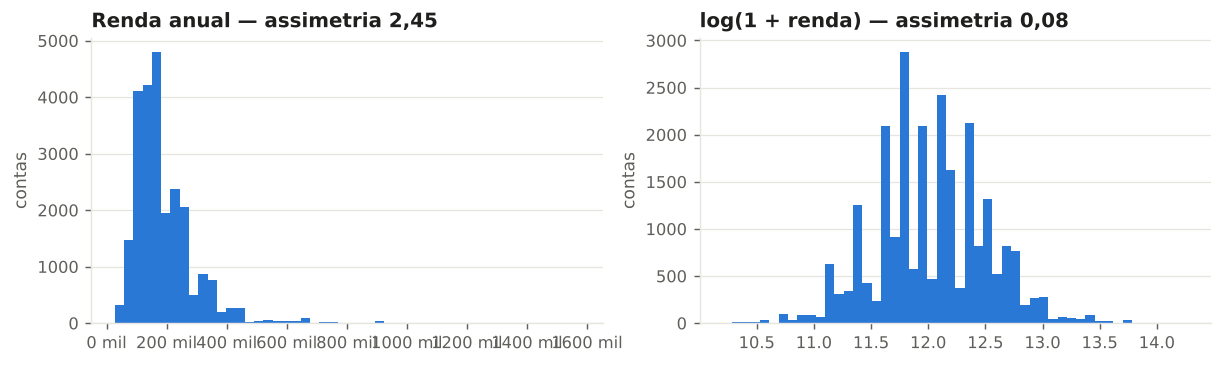

In [11]:
base = limpo[limpo["ID"].isin(alvo["ID"])]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 2.9))
axes[0].hist(base["AMT_INCOME_TOTAL"], bins=50, color=COR_BOM)
axes[0].set_title(f"Renda anual — assimetria {base['AMT_INCOME_TOTAL'].skew():.2f}".replace(".", ","))
axes[0].xaxis.set_major_formatter(lambda v, _: f"{v/1e3:.0f} mil")
axes[1].hist(np.log1p(base["AMT_INCOME_TOTAL"]), bins=50, color=COR_BOM)
axes[1].set_title(f"log(1 + renda) — assimetria {np.log1p(base['AMT_INCOME_TOTAL']).skew():.2f}".replace(".", ","))
for ax in axes:
    ax.set_ylabel("contas")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "02_log_renda")
plt.show()

**Escolha e justificativa.**

- **Padronização (`StandardScaler`)** para regressão logística e KNN. A logística usa
  regularização, que penaliza coeficientes pelo tamanho, e o KNN calcula distâncias: nos dois
  casos uma variável em centenas de milhares (renda) esmagaria uma em unidades (filhos) se
  não estivessem na mesma escala. `MinMaxScaler` foi descartado porque é dominado pelos
  extremos, e a renda tem cauda longa.
- **Log antes de padronizar** nas variáveis de cauda longa (renda, renda por membro e as
  contagens de histórico). O gráfico mostra o efeito na renda: a assimetria cai de 2,45 para
  0,08.
- **Nenhuma escala** para árvore de decisão, Random Forest e Gradient Boosting. Árvores só
  comparam "maior ou menor que um corte"; escalar não muda nenhuma decisão.

**Onde é aplicada.** Nada é escalado neste notebook. O scaler faz parte do `Pipeline`
(`build_preprocessor`, em `src/models.py`) e é ajustado só com os dados de treino de cada
fold. Ajustá-lo aqui, na base inteira, usaria média e desvio do teste para transformar o
treino.

## 6. Feature engineering

**Justificativa.** Foram criados dois grupos de atributos.

**(1) Derivados da ficha cadastral** (`build_features`):
- `INCOME_PER_MEMBER` = renda ÷ tamanho da família. A mesma renda sustenta uma pessoa ou
  cinco; a capacidade de pagamento está na renda por pessoa.
- `EMPLOYED_SHARE` = tempo no emprego atual ÷ anos de vida adulta (idade − 18). Dez anos de
  emprego significam coisas diferentes aos 30 e aos 60; a razão mede estabilidade
  relativa à idade.

In [12]:
feat = build_features(limpo)
feat.loc[feat["ID"].isin(alvo["ID"]),
         ["AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS", "INCOME_PER_MEMBER", "AGE_YEARS",
          "YEARS_EMPLOYED", "FLAG_NO_JOB", "EMPLOYED_SHARE"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,24566.0,189099.02,102368.01,27000.00,121500.00,162000.00,225000.00,1575000.00
CNT_FAM_MEMBERS,24566.0,2.21,0.88,1.00,2.00,2.00,3.00,5.00
INCOME_PER_MEMBER,24566.0,100745.14,72563.57,7560.00,56250.00,78750.00,123750.00,900000.00
AGE_YEARS,24566.0,43.95,11.26,21.24,34.56,42.78,53.19,68.86
YEARS_EMPLOYED,24566.0,6.32,6.60,0.00,1.26,4.59,8.94,43.02
FLAG_NO_JOB,24566.0,0.16,0.37,0.00,0.00,0.00,0.00,1.00
EMPLOYED_SHARE,24566.0,0.29,0.27,0.00,0.06,0.23,0.46,1.00


**(2) Histórico anterior do cliente** (`build_history_features`). A EDA mostrou que a ficha
discrimina pouco e que o comportamento passado discrimina muito. Como 68% dos clientes têm
mais de uma conta, para cada solicitação é possível olhar como o **mesmo cliente** se
comportou nas **outras contas, antes** da data do pedido:

| Atributo | O que mede |
|---|---|
| `HIST_HAS` | 1 se o cliente já tinha alguma conta antes deste pedido |
| `HIST_N_ACCOUNTS` | quantas contas anteriores |
| `HIST_MONTHS` | total de meses de histórico nessas contas |
| `HIST_WORST_STATUS` | pior atraso já registrado (−1 nada consta, 0 = 1–29 dias … 5 = 150+ dias) |
| `HIST_LAST_STATUS` | pior situação no mês imediatamente anterior ao pedido |
| `HIST_MONTHS_30PLUS` | número de meses com atraso de 30 dias ou mais |
| `HIST_SHARE_LATE` | fração dos meses com algum atraso |

**Cuidado com vazamento temporal.** O alvo é medido do mês de abertura da conta em diante. O
histórico usa somente meses **estritamente anteriores** à abertura (`MONTHS_BALANCE <
OPEN_MONTH`) e somente de **outras** contas. Não há sobreposição: é exatamente a informação
que o banco teria no dia do pedido. A célula abaixo confere isso com `assert`.

**O que ficou de fora de propósito.** O mês de abertura e o número de meses observados da
própria conta não entram como atributos. O primeiro é data de calendário, que não se repete
no futuro; o segundo só é conhecido depois da concessão.

In [13]:
contas = feat.merge(alvo, on="ID")
hist = build_history_features(contas, cr, donos=feat[["ID", GROUP]])
display(hist.drop(columns="ID").describe().T.round(2))

# Conferência: nenhum mês usado no histórico pode ser igual ou posterior à abertura da conta.
dono = feat[["ID", GROUP]]
pares = (contas[["ID", GROUP, "OPEN_MONTH"]]
         .merge(cr[["ID", "MONTHS_BALANCE"]].merge(dono, on="ID").rename(columns={"ID": "ID_OUTRA"}),
                on=GROUP))
usados = pares[(pares["ID_OUTRA"] != pares["ID"]) & (pares["MONTHS_BALANCE"] < pares["OPEN_MONTH"])]
assert (usados["MONTHS_BALANCE"] < usados["OPEN_MONTH"]).all()
assert (usados["ID_OUTRA"] != usados["ID"]).all()
print(f"Contas com histórico anterior do mesmo cliente: {hist['HIST_HAS'].mean():.1%}")
print(f"Mês mais recente usado no histórico, em relação à abertura: "
      f"{(usados['MONTHS_BALANCE'] - usados['OPEN_MONTH']).max()} (sempre negativo = sempre antes)")

,count,mean,std,min,25%,50%,75%,max
HIST_N_ACCOUNTS,24566.0,2.25,2.79,0.0,0.0,1.00,3.00,34.0
HIST_MONTHS,24566.0,30.87,46.95,0.0,0.0,12.00,42.00,463.0
HIST_WORST_STATUS,24566.0,-0.24,0.77,-1.0,-1.0,0.00,0.00,5.0
HIST_MONTHS_30PLUS,24566.0,0.38,1.82,0.0,0.0,0.00,0.00,70.0
HIST_SHARE_LATE,24566.0,0.36,0.36,0.0,0.0,0.31,0.65,1.0
HIST_LAST_STATUS,24566.0,-0.53,0.59,-1.0,-1.0,-1.00,0.00,5.0
HIST_HAS,24566.0,0.66,0.47,0.0,0.0,1.00,1.00,1.0


Contas com histórico anterior do mesmo cliente: 65.8%
Mês mais recente usado no histórico, em relação à abertura: -1 (sempre negativo = sempre antes)


**Leitura.** 65,8% das contas têm histórico anterior do mesmo cliente; as demais 34,2% são
primeiras contas e ficam com `HIST_HAS = 0`, contagens zeradas e status −1. O mês mais
recente usado no histórico é sempre o mês −1 em relação à abertura: nenhuma informação do
período em que o alvo é medido entra nos atributos.

## 7. Salvar dataset tratado

In [14]:
df = build_dataset(app, credit)     # mesmo passo a passo acima, encapsulado em src/preprocessing.py
assert df[TARGET].sum() == alvo[TARGET].sum() and len(df) == len(alvo)
assert df[FEATURE_SETS["cadastro_historico"]].isna().sum().sum() == 0
save_processed(df)
print("Salvo em data/processed/dataset_tratado.csv:", df.shape)
print(f"Clientes distintos: {df[GROUP].nunique():,} | maus: {df[TARGET].sum()} ({df[TARGET].mean():.2%})")
df[["ID", GROUP, TARGET] + FEATURE_SETS["cadastro_historico"]].head()

Salvo em data/processed/dataset_tratado.csv: (24566, 32)
Clientes distintos: 7,946 | maus: 370 (1.51%)


,ID,ID_CLIENTE,MAU_PAGADOR,CNT_CHILDREN,CNT_FAM_MEMBERS,AMT_INCOME_TOTAL,INCOME_PER_MEMBER,AGE_YEARS,YEARS_EMPLOYED,EMPLOYED_SHARE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,FLAG_NO_JOB,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,HIST_N_ACCOUNTS,HIST_MONTHS,HIST_WORST_STATUS,HIST_LAST_STATUS,HIST_MONTHS_30PLUS,HIST_SHARE_LATE,HIST_HAS
0,5008804,C000000,0,0,2,427500.0,213750.0,32.87,12.44,0.8366,0,1,1,1,0,0,0,Working,Higher education,Civil marriage,Rented apartment,Not informed,0,0,-1,-1,0,0.0,0
1,5008805,C000000,0,0,2,427500.0,213750.0,32.87,12.44,0.8366,0,1,1,1,0,0,0,Working,Higher education,Civil marriage,Rented apartment,Not informed,1,1,-1,-1,0,0.0,1
2,5008806,C000001,0,0,2,112500.0,56250.0,58.79,3.10,0.0760,0,1,1,0,0,0,0,Working,Secondary / secondary special,Married,House / apartment,Security staff,0,0,-1,-1,0,0.0,0
3,5008810,C000002,0,0,1,270000.0,270000.0,52.32,8.35,0.2433,1,0,1,0,1,1,0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,Sales staff,1,12,0,-1,0,0.5,1
4,5008811,C000002,0,0,1,270000.0,270000.0,52.32,8.35,0.2433,1,0,1,0,1,1,0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,Sales staff,0,0,-1,-1,0,0.0,0


**Resultado.** `data/processed/dataset_tratado.csv` tem 24.566 contas de 7.946 clientes, sem
nulos, com 19 atributos da ficha cadastral, 7 de histórico anterior, o alvo `MAU_PAGADOR` e
o agrupador `ID_CLIENTE`. As colunas `OPEN_MONTH`, `MONTHS_OBSERVED` e `WORST_STATUS_WINDOW`
ficam no arquivo apenas para auditoria e não são usadas como atributos.

No notebook 03 são comparados dois conjuntos de atributos: **só a ficha** (vale para
qualquer solicitante) e **ficha + histórico** (aproveita o que o banco já sabe de quem já é
cliente).